***Cell Filtering, Normalization, and Dimensionality Reduction (In multiplexed single-cell experiments (such as 10x Genomics Flex/Fixed RNA Profiling, CellPlex, or HTO/barcoding protocols), a single physical sample/file contains multiple experimental conditions tagged by distinct barcodes (BC01 to BC04)).***

In [255]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import harmonypy as hm
import random
import os


In [256]:
SEED = 7
np.random.seed(SEED)
random.seed(SEED)


In [257]:
input_dir = "/Users/tank/Desktop/single_cell_edna/output"
output_dir = "/Users/tank/Desktop/single_cell_edna/decontaminated"

In [258]:
# Set the filename of your single sample 
sample_adata = os.path.join(input_dir, "edna.h5ad")

# Read the single sample file directly
adata = ad.read_h5ad(sample_adata)

# Ensure gene and cell identifiers are unique
adata.var_names_make_unique()
adata.obs_names_make_unique()

# Copy expression counts into X for downstream processing
if "counts" in adata.layers:
    adata.X = adata.layers["counts"].astype(int).copy()


In [259]:
adata

AnnData object with n_obs × n_vars = 25189 × 19384
    obs: 'scDblFinder.cluster', 'scDblFinder.class', 'scDblFinder.score', 'scDblFinder.weighted', 'scDblFinder.difficulty', 'scDblFinder.cxds_score', 'scDblFinder.mostLikelyOrigin', 'scDblFinder.originAmbiguous'
    var: 'scDblFinder.selected'
    uns: 'scDblFinder.stats', 'scDblFinder.threshold'
    layers: 'counts'

In [260]:
adata.obs["sample"] = "edna"
adata.obs["library_id"] = "SC_S1_007"

# 10x Flex probe sequences (BC001-BC004).
sequence_to_probe = {
    "ACTTTAGG": "BC001",
    "AACGGGAA": "BC002",
    "AGTAGGCT": "BC003",
    "ATGTTGAC": "BC004",
}
probe_to_condition = {
    "BC001": "control_antibody_VEH",
    "BC002": "anti_IL6_antibody",
    "BC003": "DMSO",
    "BC004": "StingI",
}

# This dataset uses 16 GEM-barcode bases + 8 probe-barcode bases + a GEM-group suffix.
if not adata.obs_names.str.fullmatch(r"[ACGT]{24}-[0-9]+").all():
    raise ValueError("Unexpected cell-barcode format; check the cell names before assigning treatments.")
adata.obs["probe_sequence"] = adata.obs_names.str.slice(16, 24)
adata.obs["probe_barcode"] = adata.obs["probe_sequence"].map(sequence_to_probe)
if adata.obs["probe_barcode"].isna().any():
    raise ValueError("Unrecognized probe sequences found; check the barcode mapping.")
adata.obs["condition"] = adata.obs["probe_barcode"].map(probe_to_condition)

print(adata.obs["condition"].value_counts())
print(adata)

condition
DMSO                    7367
StingI                  6147
control_antibody_VEH    5886
anti_IL6_antibody       5789
Name: count, dtype: int64
AnnData object with n_obs × n_vars = 25189 × 19384
    obs: 'scDblFinder.cluster', 'scDblFinder.class', 'scDblFinder.score', 'scDblFinder.weighted', 'scDblFinder.difficulty', 'scDblFinder.cxds_score', 'scDblFinder.mostLikelyOrigin', 'scDblFinder.originAmbiguous', 'sample', 'library_id', 'probe_sequence', 'probe_barcode', 'condition'
    var: 'scDblFinder.selected'
    uns: 'scDblFinder.stats', 'scDblFinder.threshold'
    layers: 'counts'


In [261]:
adata.var["mt"] = adata.var_names.str.startswith("mt-")
sc.pp.calculate_qc_metrics(adata, qc_vars="mt", inplace=True, log1p=True)


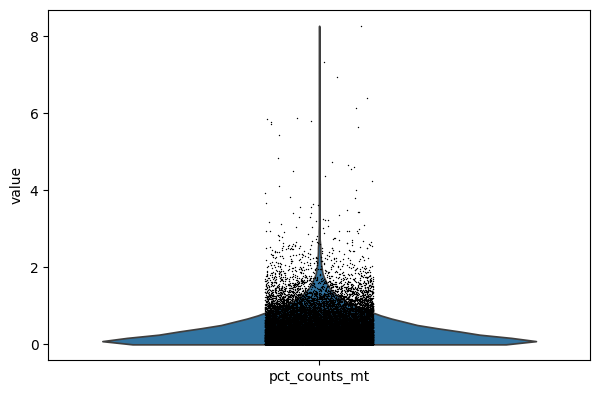

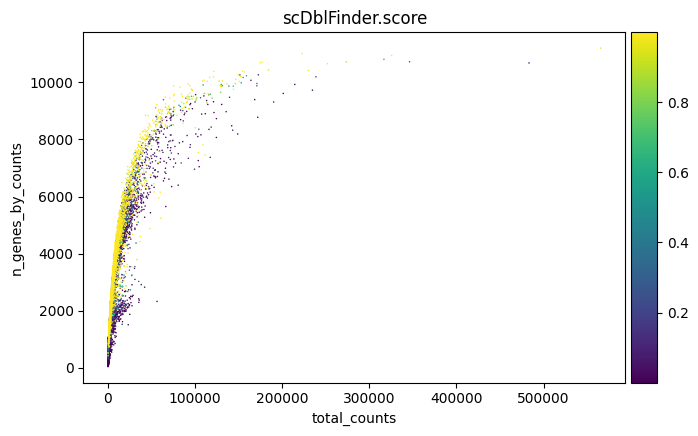

In [262]:
sc.pl.violin(adata, "pct_counts_mt")
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="scDblFinder.score")


In [263]:
print(adata.obs['sample'])
print(adata.obs['probe_sequence'])
print(adata.obs['probe_barcode'])

AAACAAGCAGATTGCAAGTAGGCT-1    edna
AAACAAGCAGCCATAAAACGGGAA-1    edna
AAACAAGCAGCCTTCAACTTTAGG-1    edna
AAACAAGCATACTTCAAGTAGGCT-1    edna
AAACAAGCATATCGCTAACGGGAA-1    edna
                              ... 
TTTGTGAGTGCACTATATGTTGAC-1    edna
TTTGTGAGTGCGTACCAACGGGAA-1    edna
TTTGTGAGTTAAGGCAAACGGGAA-1    edna
TTTGTGAGTTGCACTGAGTAGGCT-1    edna
TTTGTGAGTTTCTAAGAACGGGAA-1    edna
Name: sample, Length: 25189, dtype: category
Categories (1, object): ['edna']
AAACAAGCAGATTGCAAGTAGGCT-1    AGTAGGCT
AAACAAGCAGCCATAAAACGGGAA-1    AACGGGAA
AAACAAGCAGCCTTCAACTTTAGG-1    ACTTTAGG
AAACAAGCATACTTCAAGTAGGCT-1    AGTAGGCT
AAACAAGCATATCGCTAACGGGAA-1    AACGGGAA
                                ...   
TTTGTGAGTGCACTATATGTTGAC-1    ATGTTGAC
TTTGTGAGTGCGTACCAACGGGAA-1    AACGGGAA
TTTGTGAGTTAAGGCAAACGGGAA-1    AACGGGAA
TTTGTGAGTTGCACTGAGTAGGCT-1    AGTAGGCT
TTTGTGAGTTTCTAAGAACGGGAA-1    AACGGGAA
Name: probe_sequence, Length: 25189, dtype: category
Categories (4, object): ['AACGGGAA', 'ACTTTAGG', 'AGTAG

In [264]:
print(adata.obs['condition'])

AAACAAGCAGATTGCAAGTAGGCT-1                    DMSO
AAACAAGCAGCCATAAAACGGGAA-1       anti_IL6_antibody
AAACAAGCAGCCTTCAACTTTAGG-1    control_antibody_VEH
AAACAAGCATACTTCAAGTAGGCT-1                    DMSO
AAACAAGCATATCGCTAACGGGAA-1       anti_IL6_antibody
                                      ...         
TTTGTGAGTGCACTATATGTTGAC-1                  StingI
TTTGTGAGTGCGTACCAACGGGAA-1       anti_IL6_antibody
TTTGTGAGTTAAGGCAAACGGGAA-1       anti_IL6_antibody
TTTGTGAGTTGCACTGAGTAGGCT-1                    DMSO
TTTGTGAGTTTCTAAGAACGGGAA-1       anti_IL6_antibody
Name: condition, Length: 25189, dtype: category
Categories (4, object): ['DMSO', 'StingI', 'anti_IL6_antibody', 'control_antibody_VEH']


In [265]:
print(adata.obs['condition'].value_counts())



condition
DMSO                    7367
StingI                  6147
control_antibody_VEH    5886
anti_IL6_antibody       5789
Name: count, dtype: int64


In [266]:
print(adata)

AnnData object with n_obs × n_vars = 25189 × 19384
    obs: 'scDblFinder.cluster', 'scDblFinder.class', 'scDblFinder.score', 'scDblFinder.weighted', 'scDblFinder.difficulty', 'scDblFinder.cxds_score', 'scDblFinder.mostLikelyOrigin', 'scDblFinder.originAmbiguous', 'sample', 'library_id', 'probe_sequence', 'probe_barcode', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'scDblFinder.selected', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'scDblFinder.stats', 'scDblFinder.threshold'
    layers: 'counts'


In [267]:
adata = adata[adata.obs['scDblFinder.class'] == "singlet", :]
print(adata.obs["sample"].value_counts())
print(adata)


sample
edna    21219
Name: count, dtype: int64
View of AnnData object with n_obs × n_vars = 21219 × 19384
    obs: 'scDblFinder.cluster', 'scDblFinder.class', 'scDblFinder.score', 'scDblFinder.weighted', 'scDblFinder.difficulty', 'scDblFinder.cxds_score', 'scDblFinder.mostLikelyOrigin', 'scDblFinder.originAmbiguous', 'sample', 'library_id', 'probe_sequence', 'probe_barcode', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'scDblFinder.selected', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'scDblFinder.stats', 'scDblFinder.threshold'
    layers: 'counts'


In [268]:
adata.obs

,scDblFinder.cluster,scDblFinder.class,scDblFinder.score,scDblFinder.weighted,scDblFinder.difficulty,scDblFinder.cxds_score,scDblFinder.mostLikelyOrigin,scDblFinder.originAmbiguous,sample,library_id,...,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mt,log1p_total_counts_mt,pct_counts_mt
AAACAAGCAGATTGCAAGTAGGCT-1,10,singlet,0.000404,0.054180,0.087623,0.012756,5+7,False,edna,SC_S1_007,...,6.917706,1476,7.297768,22.967480,30.962060,44.512195,65.514905,0,0.000000,0.000000
AAACAAGCAGCCATAAAACGGGAA-1,5,singlet,0.067005,0.011441,0.133057,0.054544,2+6,False,edna,SC_S1_007,...,6.628041,954,6.861711,15.723270,26.205451,41.823899,73.270440,5,1.791759,0.524109
AAACAAGCAGCCTTCAACTTTAGG-1,5,singlet,0.000372,0.000000,0.965132,0.067007,NaN,<NA>,edna,SC_S1_007,...,6.922644,1337,7.198931,14.360509,22.363500,37.322364,61.555722,8,2.197225,0.598355
AAACAAGCATACTTCAAGTAGGCT-1,2,singlet,0.015499,0.189861,0.120689,0.078001,0+1,False,edna,SC_S1_007,...,8.385945,14833,9.604677,22.658936,28.706263,36.627789,50.535967,279,5.634790,1.880941
AAACAAGCATATCGCTAACGGGAA-1,22,singlet,0.016114,0.242128,0.114378,0.029767,6+14,False,edna,SC_S1_007,...,8.554104,18437,9.822169,18.506265,24.201334,31.648316,45.110376,143,4.969813,0.775614
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTGAGTGACATTCACTTTAGG-1,4,singlet,0.001328,0.000000,0.965132,0.020770,NaN,<NA>,edna,SC_S1_007,...,7.380879,2364,7.768533,13.197970,20.177665,31.006768,53.299492,3,1.386294,0.126904
TTTGTGAGTGCACTATATGTTGAC-1,1,singlet,0.000523,0.010318,0.043674,0.013098,4+15,False,edna,SC_S1_007,...,6.380123,701,6.553933,18.687589,30.242511,44.507846,87.303852,3,1.386294,0.427960
TTTGTGAGTTAAGGCAAACGGGAA-1,24,singlet,0.000852,0.002483,0.043674,0.000026,4+15,False,edna,SC_S1_007,...,4.454347,536,6.285998,93.470149,100.000000,100.000000,100.000000,3,1.386294,0.559701
TTTGTGAGTTGCACTGAGTAGGCT-1,2,singlet,0.006629,0.101655,0.120689,0.053786,0+1,False,edna,SC_S1_007,...,8.669056,31884,10.369891,22.741814,29.180780,36.877431,49.827500,115,4.753590,0.360682


In [269]:
sc.pp.filter_cells(adata, min_counts=200)
sc.pp.filter_cells(adata, max_counts=20_000)
print(adata.obs["sample"].value_counts())
print(adata)


/Users/tank/miniconda3/envs/single_cell/lib/python3.12/site-packages/scanpy/preprocessing/_simple.py:159: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["n_counts"] = number


sample
edna    20435
Name: count, dtype: int64
AnnData object with n_obs × n_vars = 20435 × 19384
    obs: 'scDblFinder.cluster', 'scDblFinder.class', 'scDblFinder.score', 'scDblFinder.weighted', 'scDblFinder.difficulty', 'scDblFinder.cxds_score', 'scDblFinder.mostLikelyOrigin', 'scDblFinder.originAmbiguous', 'sample', 'library_id', 'probe_sequence', 'probe_barcode', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_counts'
    var: 'scDblFinder.selected', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'scDblFinder.stats', 'scDblFinder.threshold'
    layers: 'counts'


In [270]:
sc.pp.filter_genes(adata, min_cells=20)
print(adata.obs["sample"].value_counts())
print(adata)


sample
edna    20435
Name: count, dtype: int64
AnnData object with n_obs × n_vars = 20435 × 14331
    obs: 'scDblFinder.cluster', 'scDblFinder.class', 'scDblFinder.score', 'scDblFinder.weighted', 'scDblFinder.difficulty', 'scDblFinder.cxds_score', 'scDblFinder.mostLikelyOrigin', 'scDblFinder.originAmbiguous', 'sample', 'library_id', 'probe_sequence', 'probe_barcode', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_counts'
    var: 'scDblFinder.selected', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'scDblFinder.stats', 'scDblFinder.threshold'
    layers: 'counts'


In [271]:
adata = adata[adata.obs['pct_counts_mt'] < 5, :]
print(adata.obs["sample"].value_counts())
print(adata)


sample
edna    20423
Name: count, dtype: int64
View of AnnData object with n_obs × n_vars = 20423 × 14331
    obs: 'scDblFinder.cluster', 'scDblFinder.class', 'scDblFinder.score', 'scDblFinder.weighted', 'scDblFinder.difficulty', 'scDblFinder.cxds_score', 'scDblFinder.mostLikelyOrigin', 'scDblFinder.originAmbiguous', 'sample', 'library_id', 'probe_sequence', 'probe_barcode', 'condition', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_counts'
    var: 'scDblFinder.selected', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'scDblFinder.stats', 'scDblFinder.threshold'
    layers: 'counts'


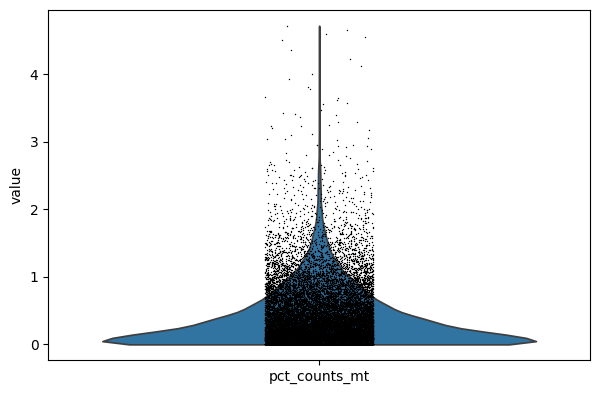

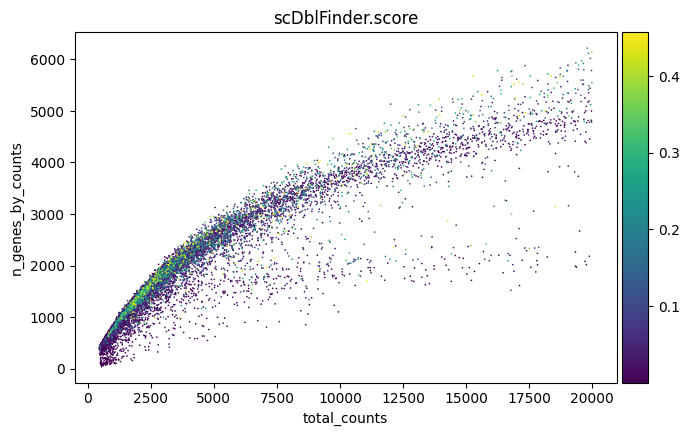

In [272]:
sc.pl.violin(adata, "pct_counts_mt")
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="scDblFinder.score")


In [273]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)
adata.raw = adata


/var/folders/j3/db7wyzrx3qzfnypdnkv5h2m40000gn/T/ipykernel_5446/1404476286.py:1: ImplicitModificationWarning: Setting element `.layers['counts']` of view, initializing view as actual.
  adata.layers["counts"] = adata.X.copy()


/var/folders/j3/db7wyzrx3qzfnypdnkv5h2m40000gn/T/ipykernel_5446/2282587332.py:1: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=2000, batch_key="sample")


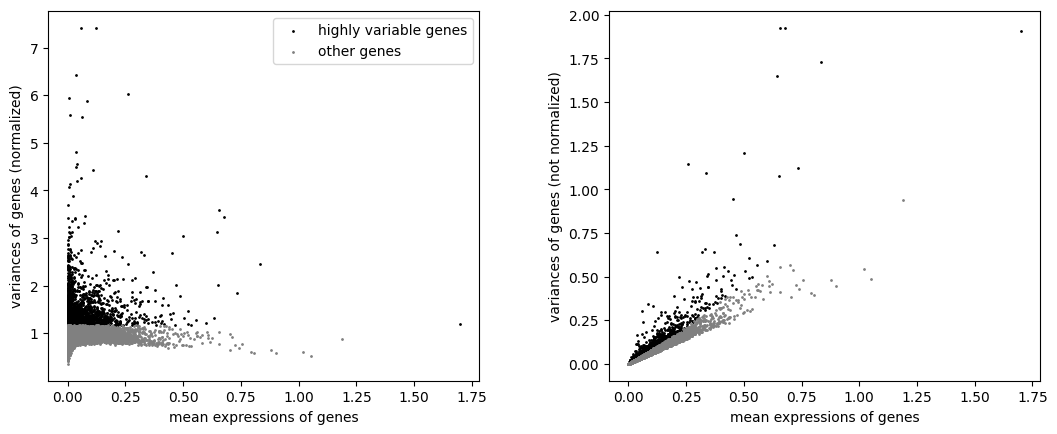

In [274]:
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=2000, batch_key="sample")
sc.pl.highly_variable_genes(adata)

/var/folders/j3/db7wyzrx3qzfnypdnkv5h2m40000gn/T/ipykernel_5446/71357201.py:1: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  sc.tl.pca(adata, svd_solver="arpack", random_state=SEED, use_highly_variable=True)


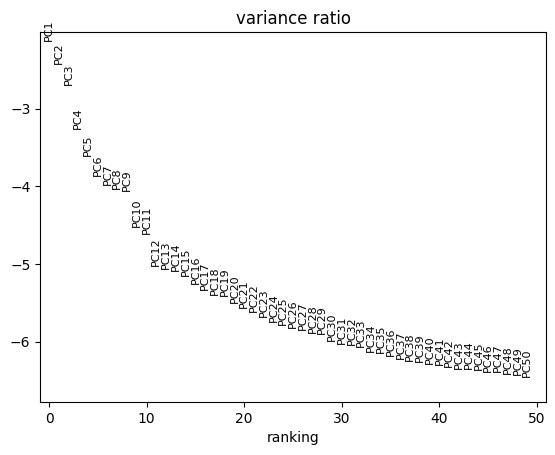

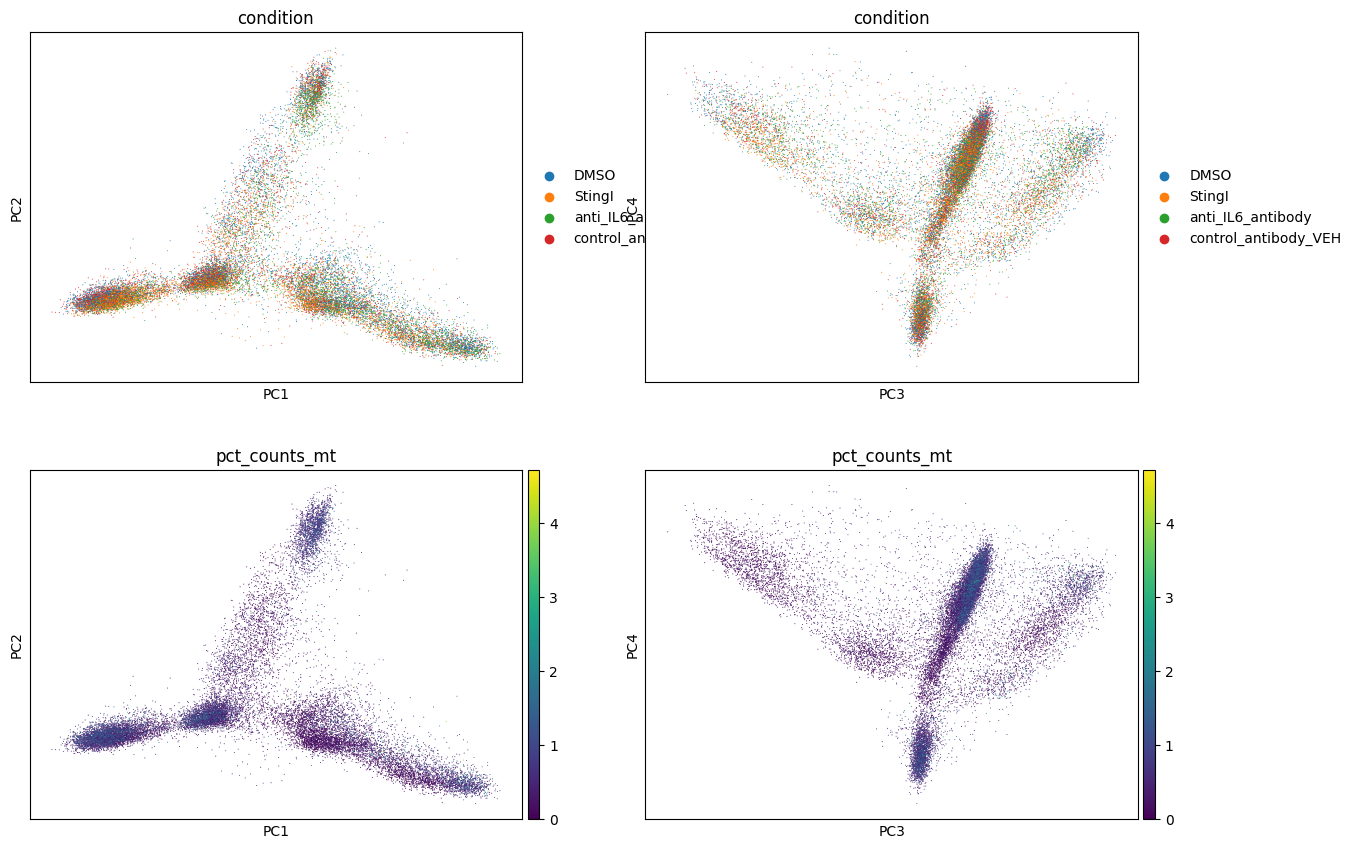

In [275]:
sc.tl.pca(adata, svd_solver="arpack", random_state=SEED, use_highly_variable=True)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)
sc.pl.pca(
    adata,
    color=["condition", "condition", "pct_counts_mt", "pct_counts_mt"],
    dimensions=[(0, 1), (2, 3), (0, 1), (2, 3)],
    ncols=2,
    size=2,
)


In [276]:
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=11, use_rep="X_pca",
                method='umap', metric='euclidean', random_state=SEED)


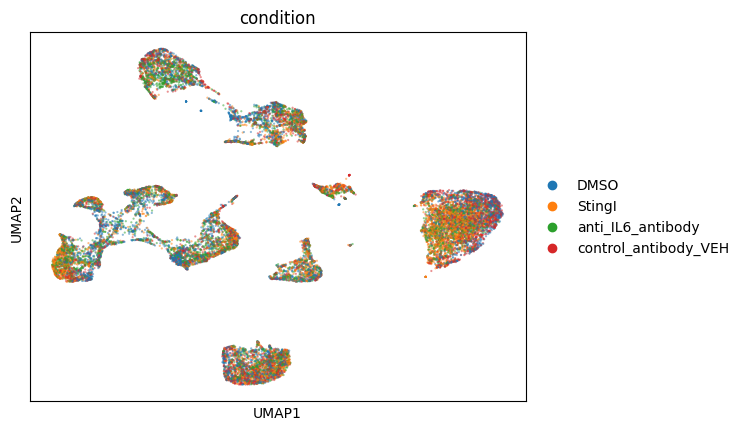

In [277]:
sc.tl.umap(adata, min_dist=0.1, spread=1.0, random_state=SEED)
sc.pl.umap(adata, color="condition", alpha=0.5, s=10)


In [278]:
adata.write(os.path.join(output_dir, "pp_and_umap_data.h5ad"))